# 03 · Feature engineering

**Objetivo:** construir variables de entrada con sentido económico, analizarlas y elegir un conjunto final compacto para las redes recurrentes.

Reglas del juego:
1. **Solo información disponible al cierre del día *t*** (todas las ventanas móviles miran hacia atrás).
2. **Solo datos de desarrollo** (objetivos anteriores a 2024): el periodo de test no se mira para elegir variables, igual que no se mirará para elegir hiperparámetros.
3. Cada variable tiene que superar tres filtros: **no ser redundante**, **tener relación con el objetivo** y que esa relación sea **estable en el tiempo** (o, si no, estar justificada por el enunciado).
4. La red recurrente ya ve los **60 últimos días** de cada variable: no hace falta fabricar variables que resuman solo esos 60 días; sí aportan las que miran **más atrás** (252 días) o que la red no puede deducir sola.

El código está en `src/oil_forecast/features.py`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

from oil_forecast.config import HORIZONS, TARGET, TEST_START
from oil_forecast.data import load_dataset, log_return_targets
from oil_forecast.features import FEATURE_GROUPS, SELECTED_FEATURES, build_candidate_features

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 80, "axes.titlesize": 12})
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", category=RuntimeWarning)

df = load_dataset()
cand = build_candidate_features(df)
start = cand.apply(lambda s: s.first_valid_index()).max()
cand = cand.loc[start:]
targets = log_return_targets(df[TARGET], HORIZONS).loc[cand.index]
test_pos = cand.index.searchsorted(pd.Timestamp(TEST_START))
dev = cand.iloc[:test_pos]
print(f"{cand.shape[1]} variables candidatas · disponibles todas desde {start:%d/%m/%Y}")
print(f"Periodo de desarrollo para el análisis: {dev.index[0]:%d/%m/%Y} - {dev.index[-1]:%d/%m/%Y}")

30 variables candidatas · disponibles todas desde 11/12/2001
Periodo de desarrollo para el análisis: 11/12/2001 - 29/12/2023


In [2]:
def dev_xy(h):
    """Development rows whose target ends before the test period."""
    n = test_pos - h
    return cand.iloc[:n], targets[f"y_{h}"].iloc[:n]

## 1. Catálogo de variables candidatas

| Grupo | Variable | Definición | Hipótesis económica |
|---|---|---|---|
| Retornos diarios | `ret_brent`, `ret_wti_fut`, `ret_gas_fut`, `ret_oro`, `ret_cobre`, `ret_indice_dolar`, `ret_usd_por_eur`, `ret_cny_por_usd` | ln(P<sub>t</sub>/P<sub>t−1</sub>) | Materia prima temporal para la red; variables pedidas en el enunciado |
| Momentum | `mom_5`, `mom_21`, `mom_63`, `mom_252` | ln(P<sub>t</sub>/P<sub>t−k</sub>) del Brent | Tendencias que se prolongan |
| Volatilidad | `vol_5`, `vol_21`, `vol_63` | desviación de los retornos en *k* días | Régimen de mercado; tras crisis, rebotes |
| | `vol_parkinson_21` | volatilidad a partir del rango máx-mín del futuro WTI | Más eficiente que la de cierres |
| Tendencia / reversión | `dist_ma50`, `dist_ma200` | distancia log a la media móvil | Sobre-extensión respecto a la tendencia |
| | `zscore_252` | z-score del log-precio en 1 año | Precio caro/barato respecto al último año |
| | `drawdown_252` | distancia al máximo del último año | Profundidad de la caída en curso |
| Estructura de mercado | `spread_brent_wti` | ln(Brent/WTI) | Prima del Brent; tiende a revertir |
| | `basis_wti` | ln(WTI spot / futuro WTI) | *Backwardation* (escasez inmediata) vs *contango* (exceso) |
| | `ratio_oro_z252`, `ratio_cobre_z252` | z-score anual de ln(oro/Brent), ln(cobre/Brent) | Valor relativo: crudo caro o barato frente a otras materias primas |
| Riesgo y política monetaria | `log_vix`, `vix_chg_5` | nivel y cambio semanal del VIX | Aversión al riesgo |
| | `tipo_bce`, `tipo_bce_chg_63` | nivel y cambio trimestral del tipo | Ciclo monetario |
| Actividad | `wti_range`, `wti_volume_z63` | rango intradía y volumen relativo del futuro WTI | Tensión / participación del mercado |

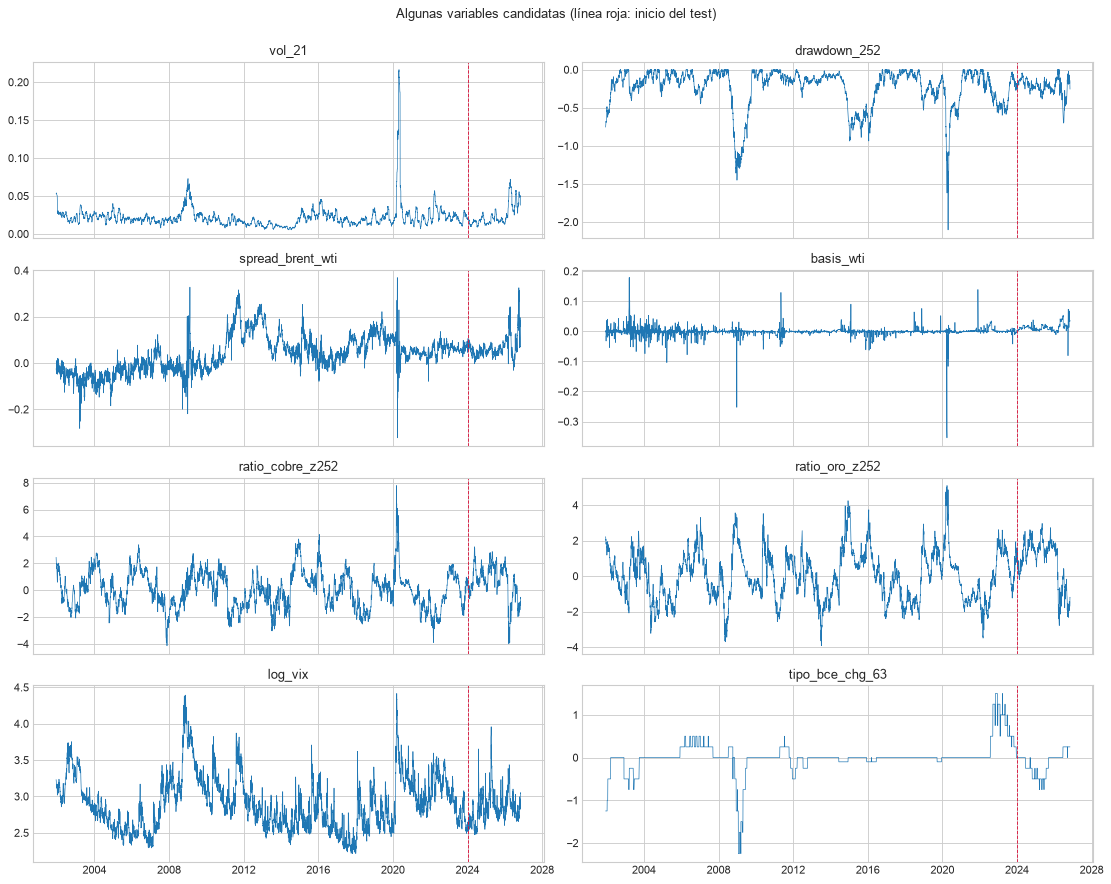

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(14, 11), sharex=True)
show = ["vol_21", "drawdown_252", "spread_brent_wti", "basis_wti", "ratio_cobre_z252", "ratio_oro_z252", "log_vix", "tipo_bce_chg_63"]
for ax, c in zip(axes.flat, show):
    ax.plot(cand.index, cand[c], lw=0.6)
    ax.axvline(pd.Timestamp(TEST_START), color="crimson", ls="--", lw=0.8)
    ax.set_title(c)
fig.suptitle("Algunas variables candidatas (línea roja: inicio del test)", y=1.0)
plt.tight_layout()

## 2. Distribuciones y valores extremos

Las redes funcionan mejor con entradas de escala parecida y sin valores desorbitados. Medimos asimetría, curtosis y qué porcentaje de días quedaría fuera de los percentiles 0,5 %-99,5 % (lo que la winsorización recortará).

In [4]:
dist = pd.DataFrame({
    "asimetría": dev.skew(),
    "curtosis": dev.kurt(),
    "% recortado": ((dev < dev.quantile(0.005)) | (dev > dev.quantile(0.995))).mean() * 100,
    "mín": dev.min(), "máx": dev.max(),
})
dist.sort_values("curtosis", ascending=False).head(10)

,asimetría,curtosis,% recortado,mín,máx
basis_wti,-7.816,204.586,1.001,-0.354,0.179
vol_5,9.464,162.027,1.001,0.002,0.388
ret_brent,-2.084,82.915,1.001,-0.644,0.412
vol_21,7.284,75.639,1.001,0.005,0.216
wti_range,5.290,54.689,1.001,0.006,0.456
vol_63,5.360,36.978,1.001,0.007,0.140
vol_parkinson_21,3.545,20.669,1.001,0.007,0.122
mom_5,-0.844,19.495,1.001,-0.869,0.537
ret_wti_fut,0.029,17.138,1.001,-0.282,0.320
mom_21,-0.979,14.601,1.001,-1.263,1.339


Los retornos diarios tienen curtosis enormes (2020, cambios de contrato de los futuros). La winsorización por fold recorta el 1 % de días más extremos, y es suficiente: el resto de variables (volatilidades, ratios, z-scores) tienen colas moderadas.

## 3. Redundancia

Dos variables casi iguales no aportan información nueva y hacen el modelo más inestable. Usamos la correlación de Spearman (robusta a extremos) y un agrupamiento jerárquico.

,variable A,variable B,ρ Spearman
3,dist_ma200,zscore_252,0.927
1,mom_21,dist_ma50,0.881
4,zscore_252,drawdown_252,0.870
2,vol_21,vol_parkinson_21,0.836
0,ret_indice_dolar,ret_usd_por_eur,-0.830
5,zscore_252,ratio_oro_z252,-0.805


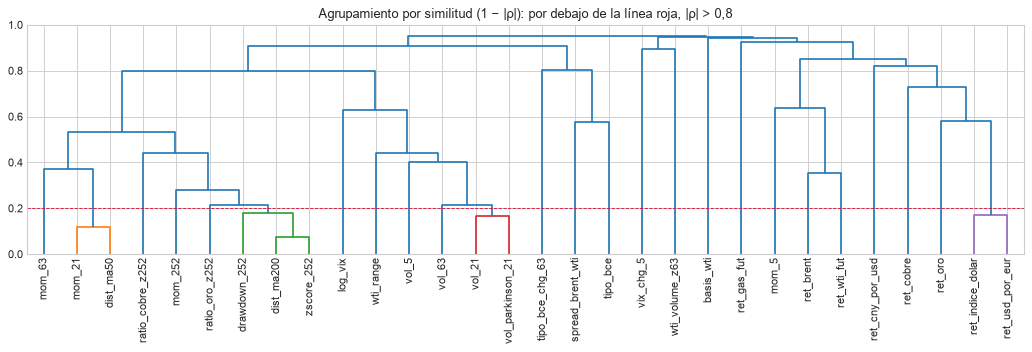

In [5]:
corr = dev.corr(method="spearman")
dist_matrix = 1 - corr.abs()
link = hierarchy.linkage(squareform(dist_matrix.values, checks=False), method="average")
fig, ax = plt.subplots(figsize=(13, 4.5))
hierarchy.dendrogram(link, labels=corr.columns.tolist(), leaf_rotation=90, ax=ax, color_threshold=0.2)
ax.axhline(0.2, color="crimson", ls="--", lw=0.8)
ax.set_title("Agrupamiento por similitud (1 − |ρ|): por debajo de la línea roja, |ρ| > 0,8")
plt.tight_layout()

pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr) for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) > 0.8]
pd.DataFrame(pairs, columns=["variable A", "variable B", "ρ Spearman"]).sort_values("ρ Spearman", key=abs, ascending=False)

Grupos redundantes: **`dist_ma200` ≈ `zscore_252` ≈ `drawdown_252`** (las tres miden si el precio está alto o bajo respecto al último año), **`mom_21` ≈ `dist_ma50`**, **`vol_21` ≈ `vol_parkinson_21`** e **índice dólar ≈ USD/EUR** (el euro pesa el 58 % del índice). De cada grupo se conservará como máximo una.

## 4. Relevancia: ¿se relaciona cada variable con el retorno futuro?

Correlación de Spearman entre cada variable en *t* y el retorno del Brent de *t* a *t+h*, en el periodo de desarrollo.

> **Cuidado con el tamaño muestral efectivo:** a 252 días, dos objetivos consecutivos comparten 251 días, así que en 2001-2023 hay en realidad unas **22 observaciones independientes**, no 5.000. Correlaciones de ±0,2 pueden ser casualidad: por eso se exige además estabilidad (sección 5) y comprobación fuera de muestra (sección 6).

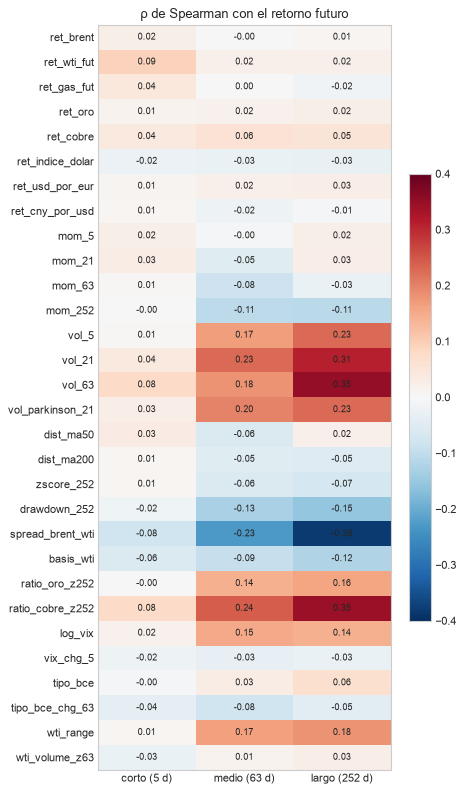

In [6]:
rho = pd.DataFrame({f"{n} ({h} d)": dev_xy(h)[0].corrwith(dev_xy(h)[1], method="spearman") for n, h in HORIZONS.items()})
fig, ax = plt.subplots(figsize=(6, 10))
im = ax.imshow(rho, cmap="RdBu_r", vmin=-0.4, vmax=0.4, aspect="auto")
ax.set_yticks(range(len(rho)), rho.index); ax.set_xticks(range(3), rho.columns)
for i in range(len(rho)):
    for j in range(3):
        ax.text(j, i, f"{rho.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im, shrink=0.6); ax.set_title("ρ de Spearman con el retorno futuro")
plt.tight_layout()

- **A 5 días casi todo es ruido** (|ρ| < 0,1). Destaca el **retorno del futuro WTI** (el efecto del desfase horario visto en el EDA) y el ratio cobre/Brent.
- **A 63 y 252 días aparecen relaciones de régimen:** la **volatilidad alta** precede a rebotes (tras los desplomes de 2008, 2015 y 2020 el precio se recuperó), una **prima del Brent sobre el WTI alta** precede a caídas del Brent, y un **crudo barato frente al cobre** precede a subidas (valor relativo).

## 5. Estabilidad: ¿la relación se mantiene en distintas épocas?

Nº de subperiodos (de 3) en los que la correlación tiene el mismo signo que en todo el periodo:


,ret_brent,ret_wti_fut,ret_gas_fut,ret_oro,ret_cobre,ret_indice_dolar,ret_usd_por_eur,ret_cny_por_usd,mom_5,mom_21,...,spread_brent_wti,basis_wti,ratio_oro_z252,ratio_cobre_z252,log_vix,vix_chg_5,tipo_bce,tipo_bce_chg_63,wti_range,wti_volume_z63
corto,2,3,3,2,3,2,2,3,2,2,...,3,3,1,3,2,2,2,3,2,3
medio,2,2,1,2,3,3,2,1,2,2,...,3,3,3,3,2,2,1,3,2,1
largo,2,2,3,2,3,3,3,2,2,1,...,3,3,3,3,2,3,1,3,2,2


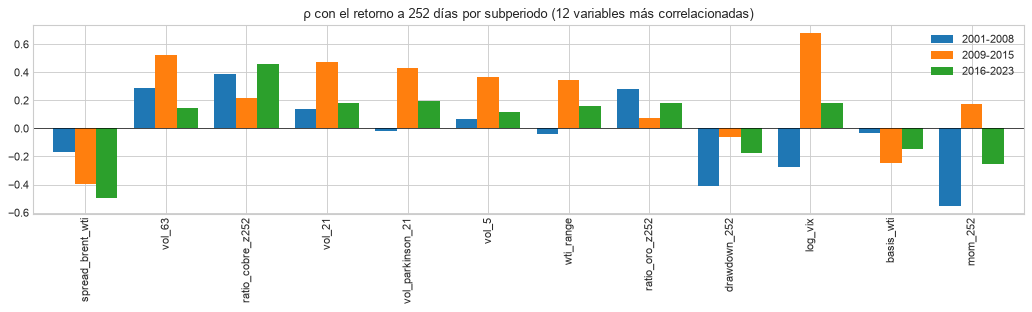

In [7]:
periods = [("2001", "2008"), ("2009", "2015"), ("2016", "2023")]
stab = {}
for n, h in HORIZONS.items():
    X, y = dev_xy(h)
    sub = pd.DataFrame({f"{a}-{b}": X.loc[a:b].corrwith(y.loc[a:b], method="spearman") for a, b in periods})
    stab[n] = np.sign(sub).eq(np.sign(rho[f"{n} ({h} d)"]), axis=0).sum(axis=1)
stab = pd.DataFrame(stab)

X, y = dev_xy(252)
sub252 = pd.DataFrame({f"{a}-{b}": X.loc[a:b].corrwith(y.loc[a:b], method="spearman") for a, b in periods})
fig, ax = plt.subplots(figsize=(13, 4))
sub252.loc[rho["largo (252 d)"].abs().sort_values(ascending=False).index[:12]].plot(kind="bar", ax=ax, width=0.8)
ax.axhline(0, color="k", lw=0.6); ax.set_title("ρ con el retorno a 252 días por subperiodo (12 variables más correlacionadas)")
plt.tight_layout()
print("Nº de subperiodos (de 3) en los que la correlación tiene el mismo signo que en todo el periodo:")
stab.T

Una relación que cambia de signo según la época (por ejemplo el nivel del tipo del BCE, estable solo en 1 de 3 subperiodos a medio y largo plazo) no es una regla en la que confiar.

- **Estables en los tres subperiodos y en los tres horizontes:** `spread_brent_wti`, `basis_wti`, `ratio_cobre_z252`, `drawdown_252`, `tipo_bce_chg_63` y `ret_cobre`.
- **Estables a 63 y 252 días:** `ratio_oro_z252`.
- **Estables solo a 252 días:** las volatilidades (`vol_21`, `vol_63`).

## 6. Comprobación fuera de muestra con un modelo no lineal

La correlación solo mide relaciones monótonas y dentro de la muestra. Como prueba complementaria entrenamos un modelo de árboles sencillo (*gradient boosting*) con **datos hasta 2018** y medimos en **2019-2023** cuánto empeora el error al desordenar cada variable (*importancia por permutación*). Si desordenar una variable no empeora el error, el modelo no la necesita para generalizar.

> Este modelo no es uno de los del trabajo: solo sirve como "segunda opinión" sobre las variables.

,MSE modelo / MSE ingenuo
horizonte,
corto,1.018
medio,1.175
largo,0.890


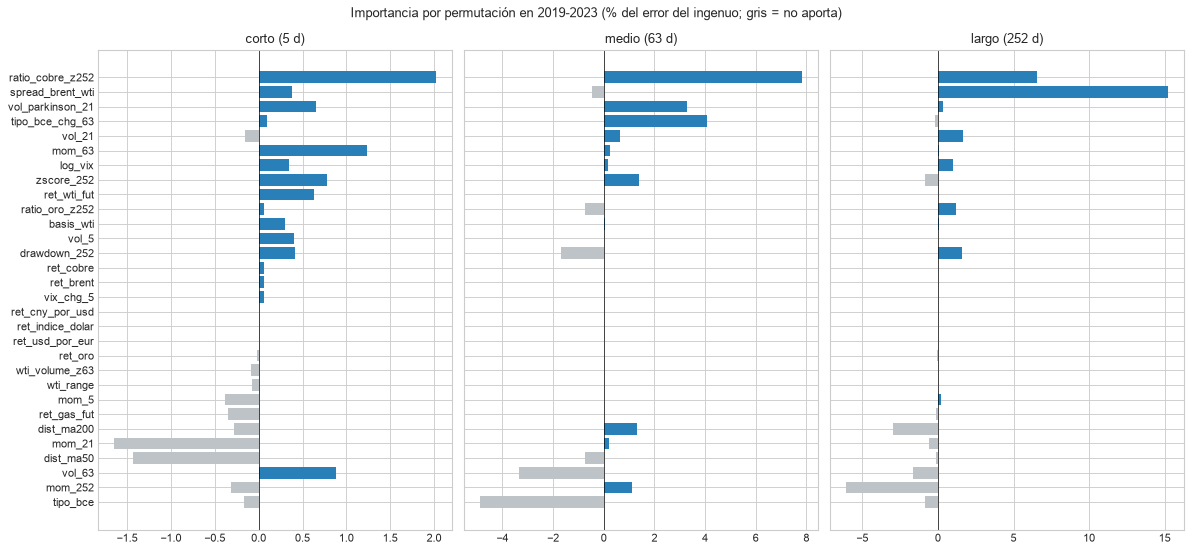

In [8]:
val_pos = cand.index.searchsorted(pd.Timestamp("2019-01-01"))
perm, skill_rows = {}, []
for n, h in HORIZONS.items():
    y_all = targets[f"y_{h}"]
    X_tr, y_tr = cand.iloc[:val_pos - h], y_all.iloc[:val_pos - h]
    X_va, y_va = cand.iloc[val_pos:test_pos - h], y_all.iloc[val_pos:test_pos - h]
    model = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200,
                                          min_samples_leaf=100, random_state=0).fit(X_tr, y_tr)
    naive_mse = np.mean(y_va ** 2)
    skill_rows.append({"horizonte": n, "MSE modelo / MSE ingenuo": np.mean((y_va - model.predict(X_va)) ** 2) / naive_mse})
    pi = permutation_importance(model, X_va, y_va, n_repeats=10, random_state=0, scoring="neg_mean_squared_error")
    perm[n] = pd.Series(pi.importances_mean / naive_mse * 100, index=cand.columns)
perm = pd.DataFrame(perm)
display(pd.DataFrame(skill_rows).set_index("horizonte"))

fig, axes = plt.subplots(1, 3, figsize=(15, 7), sharey=True)
order = perm.mean(axis=1).sort_values().index
for ax, n in zip(axes, HORIZONS):
    vals = perm.loc[order, n]
    ax.barh(order, vals, color=np.where(vals > 0, "#2980b9", "#bdc3c7"))
    ax.axvline(0, color="k", lw=0.6); ax.set_title(f"{n} ({HORIZONS[n]} d)")
fig.suptitle("Importancia por permutación en 2019-2023 (% del error del ingenuo; gris = no aporta)")
plt.tight_layout()

- El modelo de árboles **no bate al ingenuo a 5 ni a 63 días** en 2019-2023 y sí algo a 252 días: anticipa lo que veremos con las redes.
- Las que más aportan fuera de muestra coinciden con las más estables: **ratio cobre/Brent** y **diferencial Brent-WTI** (con diferencia), seguidas de la **volatilidad**, el **cambio del tipo del BCE** y el **VIX**.
- Cuando dos variables están correlacionadas (por ejemplo `vol_21` y `vol_63`), la importancia por permutación se reparte entre ambas y puede salir negativa en una de ellas: por eso este criterio se combina con los anteriores y no se usa solo.
- Varias variables tienen importancia **negativa**: el modelo las usa en el train pero empeoran la validación (sobreajuste). Son candidatas claras a eliminar (`mom_252`, `dist_ma200`, `tipo_bce`, `dist_ma50`…).

## 7. Selección final

Combinamos los criterios. Los **retornos diarios** de las variables que pide el enunciado se mantienen aunque su correlación con el retorno futuro sea baja: son la secuencia sobre la que trabaja la capa recurrente (la red puede encontrar patrones temporales que una correlación no mide), y solo se elimina el que es redundante.

In [9]:
decisions = {
    "ret_brent": (True, "serie objetivo: materia prima de la red"),
    "ret_wti_fut": (True, "única señal adelantada clara (retardo 1)"),
    "ret_gas_fut": (True, "exógena del enunciado (energía)"),
    "ret_oro": (True, "exógena del enunciado (refugio)"),
    "ret_cobre": (True, "exógena del enunciado (actividad industrial)"),
    "ret_indice_dolar": (True, "exógena del enunciado (dólar)"),
    "ret_usd_por_eur": (False, "redundante con el índice dólar (ρ = −0,83)"),
    "ret_cny_por_usd": (True, "exógena del enunciado (China)"),
    "mom_5": (False, "la red ya ve los últimos 60 retornos"),
    "mom_21": (False, "la red ya ve los últimos 60 retornos; redundante con dist_ma50"),
    "mom_63": (False, "la red ya ve los últimos 60 retornos"),
    "mom_252": (False, "importancia fuera de muestra muy negativa (sobreajuste)"),
    "vol_5": (False, "ruidosa y contenida en la ventana"),
    "vol_21": (True, "relevante a 63 y 252 días"),
    "vol_63": (True, "la ρ más alta y estable a 252 días; su importancia negativa se debe a que comparte información con vol_21"),
    "vol_parkinson_21": (False, "redundante con vol_21 (ρ = 0,84)"),
    "dist_ma50": (False, "redundante con mom_21; importancia negativa"),
    "dist_ma200": (False, "redundante con zscore/drawdown; importancia negativa"),
    "zscore_252": (False, "redundante con dist_ma200 y drawdown_252"),
    "drawdown_252": (True, "estable; resume el último año (más allá de la ventana)"),
    "spread_brent_wti": (True, "la relación más fuerte a largo plazo, estable"),
    "basis_wti": (True, "estable en los 3 horizontes (escasez vs exceso)"),
    "ratio_oro_z252": (True, "estable a 63 y 252 días"),
    "ratio_cobre_z252": (True, "relevante, estable y útil fuera de muestra"),
    "log_vix": (True, "régimen de riesgo; relevante a 63 y 252 días"),
    "vix_chg_5": (False, "sin relevancia; la red ya ve la evolución del VIX"),
    "tipo_bce": (False, "no estacionaria, signo inestable, importancia negativa"),
    "tipo_bce_chg_63": (True, "estable y útil fuera de muestra"),
    "wti_range": (False, "solapa con la volatilidad; importancia nula"),
    "wti_volume_z63": (False, "sin relevancia"),
}
group_of = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
table = pd.DataFrame({
    "grupo": pd.Series(group_of),
    "ρ 5d": rho.iloc[:, 0], "ρ 63d": rho.iloc[:, 1], "ρ 252d": rho.iloc[:, 2],
    "estable c/m/l": stab.astype(str).agg("/".join, axis=1),
    "perm. media": perm.mean(axis=1),
    "seleccionada": pd.Series({k: "✔" if v[0] else "" for k, v in decisions.items()}),
    "motivo": pd.Series({k: v[1] for k, v in decisions.items()}),
}).loc[cand.columns]
selected = [k for k, (keep, _) in decisions.items() if keep]
assert set(selected) == set(SELECTED_FEATURES), "la selección debe coincidir con features.SELECTED_FEATURES"
table

,grupo,ρ 5d,ρ 63d,ρ 252d,estable c/m/l,perm. media,seleccionada,motivo
ret_brent,Retornos diarios,0.025,-0.000,0.009,2/2/2,0.020,✔,serie objetivo: materia prima de la red
ret_wti_fut,Retornos diarios,0.092,0.020,0.021,3/2/2,0.210,✔,única señal adelantada clara (retardo 1)
ret_gas_fut,Retornos diarios,0.043,0.001,-0.015,3/1/3,-0.168,✔,exógena del enunciado (energía)
ret_oro,Retornos diarios,0.013,0.016,0.022,2/2/2,-0.017,✔,exógena del enunciado (refugio)
ret_cobre,Retornos diarios,0.039,0.057,0.051,3/3/3,0.020,✔,exógena del enunciado (actividad industrial)
ret_indice_dolar,Retornos diarios,-0.023,-0.027,-0.030,2/3/3,0.003,✔,exógena del enunciado (dólar)
ret_usd_por_eur,Retornos diarios,0.010,0.019,0.028,2/2/3,0.000,,"redundante con el índice dólar (ρ = −0,83)"
ret_cny_por_usd,Retornos diarios,0.008,-0.021,-0.005,3/1/2,0.007,✔,exógena del enunciado (China)
mom_5,Momentum del Brent,0.023,-0.005,0.024,2/2/2,-0.056,,la red ya ve los últimos 60 retornos
mom_21,Momentum del Brent,0.030,-0.049,0.025,2/2/1,-0.669,,la red ya ve los últimos 60 retornos; redundan...


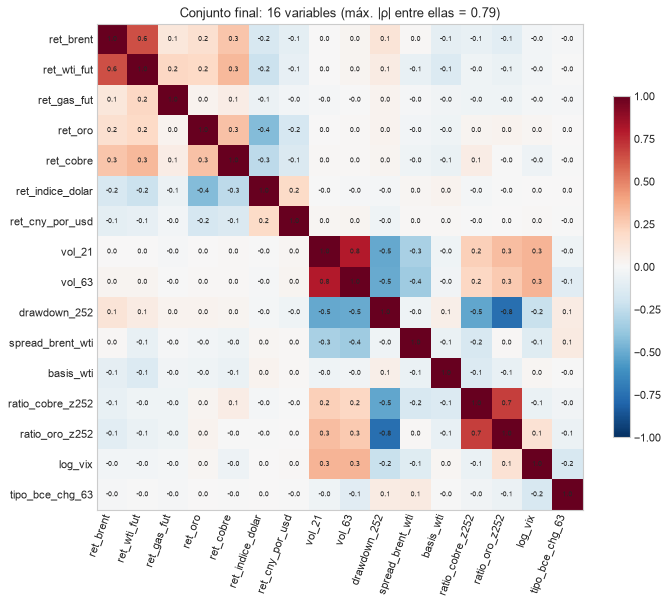

In [10]:
final = cand[SELECTED_FEATURES]
fc = final.loc[: TEST_START].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(fc, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(fc)), fc.columns, rotation=70, ha="right"); ax.set_yticks(range(len(fc)), fc.columns)
for i in range(len(fc)):
    for j in range(len(fc)):
        ax.text(j, i, f"{fc.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6)
ax.grid(False); fig.colorbar(im, shrink=0.7)
ax.set_title(f"Conjunto final: {len(SELECTED_FEATURES)} variables (máx. |ρ| entre ellas = {fc.where(~np.eye(len(fc), dtype=bool)).abs().max().max():.2f})")
plt.tight_layout()

## Resumen

- De **30 candidatas** se seleccionan **16 variables**, que se usarán **igual en las tres redes y en los tres horizontes** (condiciones iguales, como pide el enunciado):

| Grupo | Variables |
|---|---|
| Retornos diarios (7) | Brent, futuro WTI, futuro gas, oro, cobre, índice dólar, yuan |
| Régimen (3) | volatilidad 21 y 63 días, caída desde el máximo anual |
| Estructura y valor relativo (4) | diferencial Brent-WTI, *basis* del WTI, ratios cobre/Brent y oro/Brent |
| Riesgo y política monetaria (2) | log VIX, cambio trimestral del tipo del BCE |

- Todas las variables del enunciado están representadas (el USD/EUR a través del índice dólar; la cesta OPEP queda excluida en el ETL).
- Ninguna pareja de variables seleccionadas es redundante.
- La relación con el retorno futuro es **débil a 5 días y moderada a 63-252 días**: la capacidad predictiva, si existe, estará en el medio y largo plazo y en la **adaptación de la incertidumbre al régimen** (volatilidad, VIX).
- La selección se ha hecho **sin mirar el test (2024-2026)**.

Siguiente paso (notebook 04): escalado por fold, particiones walk-forward y creación de secuencias con estas 16 variables.